# 02 · Correlação e Regressão Linear (Simples e Multivariada)

**PNV-3421 — Processos Estocásticos — Previsão de Demanda**
**Ementa, tópico 2:** *"Modelos causais de previsão: correlação linear simples e multivariada"*

### De onde vem este material
Todo o conteúdo abaixo vem de `2.5/Aula 07.pdf` — que, na organização original, **não tinha nenhum notebook de apoio**. Este notebook implementa em Python toda a teoria do slide (covariância, correlação de Pearson, mínimos quadrados, análise de variação dos resíduos, regressão multivariada, colinearidade, seleção de variáveis) e resolve os 4 exercícios propostos, usando os arquivos de dados reais da pasta `2.5/` (`07 - Dados Ex 02.txt` e `07 - Dados Ex 04.xlsx`).

### Roteiro
1. Variáveis correlacionadas: covariância e coeficiente de Pearson
2. Regressão Linear Simples: mínimos quadrados, erro padrão, teste do coeficiente angular, r², previsão
3. Regressão Linear Multivariada: sistema normal, r² ajustado
4. Colinearidade: o problema e como identificá-lo
5. Seleção de variáveis independentes: método exaustivo e método aditivo (stepwise)
6. Variáveis "dummy" para categorias
7. Exercícios 1 a 4 (dados reais)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import itertools
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
rng = np.random.default_rng(7)

## 1. Variáveis Correlacionadas

A **covariância** mede a variabilidade conjunta entre duas variáveis:

$$\text{cov}(x,y) = \frac{\sum_{i=1}^n (x_i-\bar X)(y_i - \bar Y)}{n-1}$$

* $\text{cov}(x,y) > 0$: correlacionadas positivamente
* $\text{cov}(x,y) < 0$: correlacionadas negativamente
* $\text{cov}(x,y) = 0$: independentes (linearmente)

O **coeficiente de correlação de Pearson** normaliza a covariância para o intervalo $[-1, +1]$:

$$r = \frac{\text{cov}(x,y)}{\sqrt{\text{var}\,x}\sqrt{\text{var}\,y}}$$

* $r \to -1$: relação linear negativa forte
* $r \to +1$: relação linear positiva forte
* $r \to 0$: ausência de relação linear (pode ainda existir relação **não linear**!)

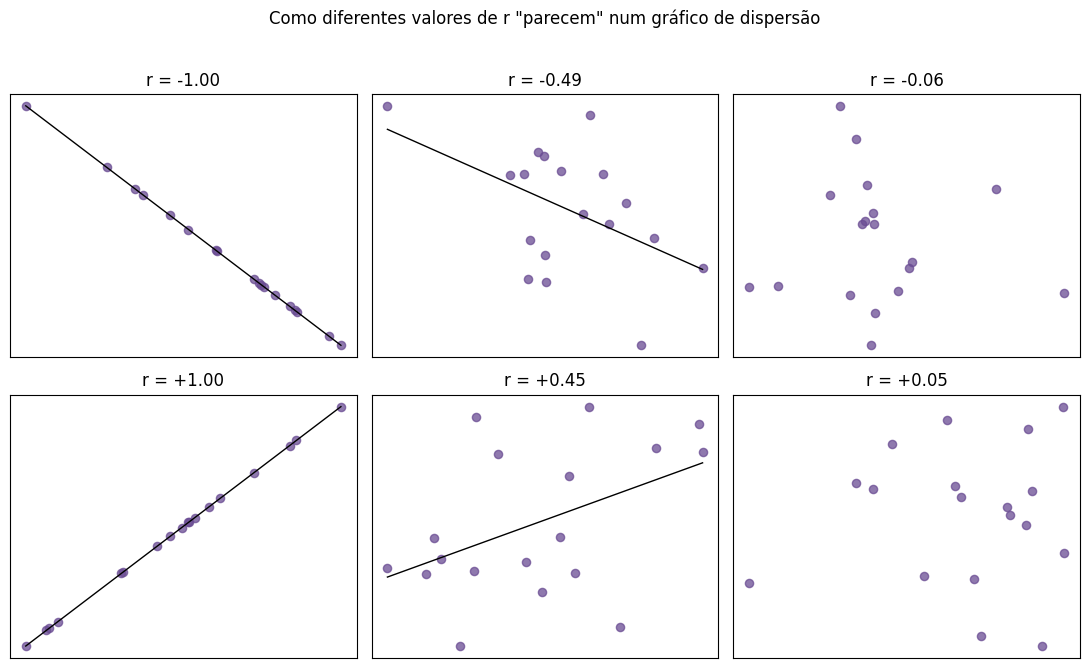

In [2]:
# Recriação lúdica da grade do slide: "sinta" visualmente o que cada r representa
def gera_com_r(r_alvo, n=18, seed=0):
    g = np.random.default_rng(seed)
    x = g.normal(0, 1, n)
    ruido = g.normal(0, 1, n)
    y = r_alvo * x + np.sqrt(max(1 - r_alvo ** 2, 1e-6)) * ruido
    return x, y

casos = [(-1.0, 1), (-0.6, 2), (0.0, 3), (1.0, 4), (0.3, 5), (0.0, 6)]
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
for ax, (r_alvo, seed) in zip(axes.ravel(), casos):
    x, y = gera_com_r(r_alvo, seed=seed)
    r_real = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, color='#6a4c93', alpha=0.75, s=35)
    if abs(r_alvo) > 0.05:
        b, b0 = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 10)
        ax.plot(xs, b0 + b * xs, color='k', lw=1)
    ax.set_title(f'r = {r_real:+.2f}')
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Como diferentes valores de r "parecem" num gráfico de dispersão', y=1.02)
fig.tight_layout()
plt.show()

## 2. Regressão Linear Simples

**Exemplo introdutório (Aula 07):** uma rede vende peças de manutenção de motores. Foram registrados o **preço** (X) e as **vendas** (Y, centenas de itens) em 10 semanas.

Coeficiente de correlação de Pearson: r = -0.8635  (há correlação linear negativa)


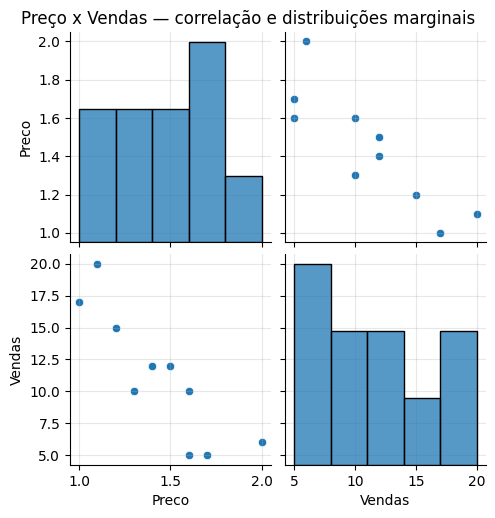

In [3]:
preco = np.array([1.3, 2.0, 1.7, 1.5, 1.6, 1.2, 1.6, 1.4, 1.0, 1.1])
vendas = np.array([10, 6, 5, 12, 10, 15, 5, 12, 17, 20])
df_pv = pd.DataFrame({'Preco': preco, 'Vendas': vendas})

r_pv = np.corrcoef(preco, vendas)[0, 1]
print(f"Coeficiente de correlação de Pearson: r = {r_pv:.4f}  (há correlação linear negativa)")

sns.pairplot(df_pv)
plt.suptitle('Preço x Vendas — correlação e distribuições marginais', y=1.02)
plt.show()

**Reta de regressão:** $\hat Y = b_0 + bX$, obtida pelo **método dos mínimos quadrados** — minimiza a soma dos erros quadráticos entre os pontos e a reta:

$$\min \sum_{i=1}^n (y_i - \hat y_i)^2 = \min \sum_{i=1}^n (y_i - (b_0+bx_i))^2$$

$$b = \frac{n\sum XY - \sum X \sum Y}{n\sum X^2 - (\sum X)^2} \qquad b_0 = \frac{\sum Y}{n} - \frac{b\sum X}{n}$$

b0 = 32.136   b = -14.539   -> Vendas = 32.136 + (-14.539) x Preço
R^2 = 0.746


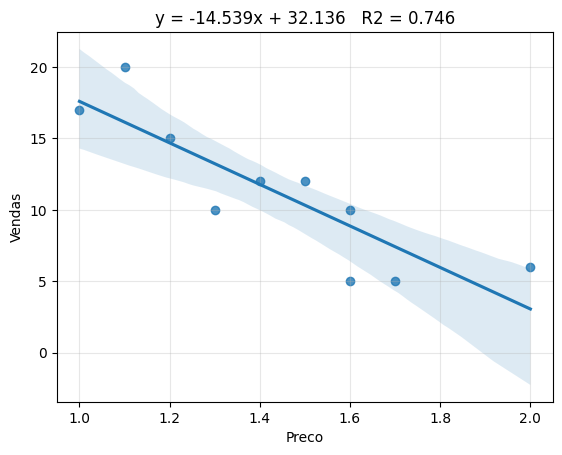

In [4]:
model_pv = ols('Vendas ~ Preco', df_pv).fit()
b0_pv, b_pv = model_pv.params['Intercept'], model_pv.params['Preco']
print(f"b0 = {b0_pv:.3f}   b = {b_pv:.3f}   -> Vendas = {b0_pv:.3f} + ({b_pv:.3f}) x Preço")
print(f"R^2 = {model_pv.rsquared:.3f}")

sns.regplot(x='Preco', y='Vendas', data=df_pv, ci=95)
plt.title(f"y = {b_pv:.3f}x + {b0_pv:.3f}   R2 = {model_pv.rsquared:.3f}")
plt.show()

### "A reta que minimiza o erro" — visto de outro ângulo

A ideia do método dos mínimos quadrados é escolher, entre **todas** as retas possíveis, aquela com o menor SSE. Vamos mostrar isso literalmente: fixamos $b_0$ no valor ótimo e variamos $b$ em torno do valor ajustado, calculando o SSE de cada reta candidata.

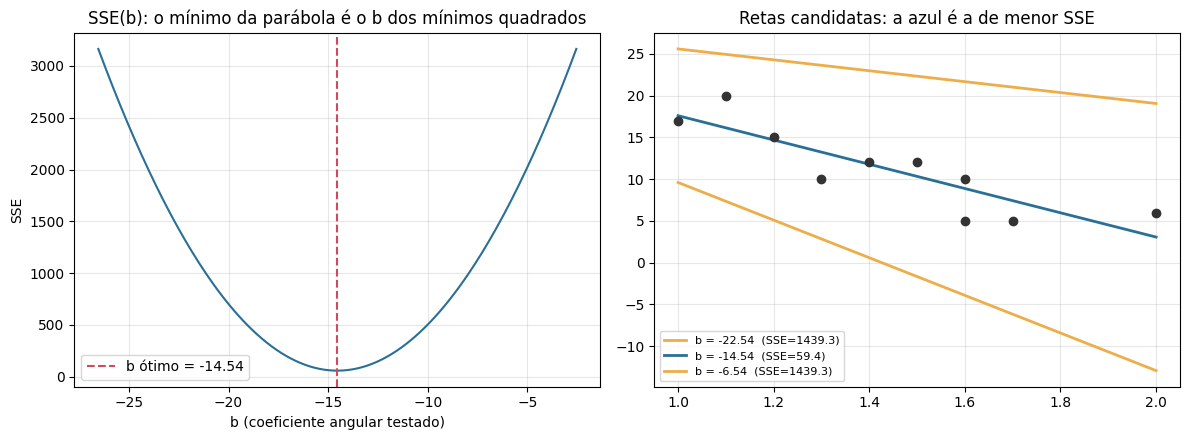

In [5]:
def sse_para_b(b_tentativa, b0_fixo=b0_pv):
    pred = b0_fixo + b_tentativa * preco
    return np.sum((vendas - pred) ** 2)

b_candidatos = np.linspace(b_pv - 12, b_pv + 12, 200)
sse_candidatos = [sse_para_b(b) for b in b_candidatos]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(b_candidatos, sse_candidatos, color='#2a6f97')
axes[0].axvline(b_pv, color='#d1495b', ls='--', label=f'b ótimo = {b_pv:.2f}')
axes[0].set_xlabel('b (coeficiente angular testado)'); axes[0].set_ylabel('SSE')
axes[0].set_title('SSE(b): o mínimo da parábola é o b dos mínimos quadrados')
axes[0].legend()

xs = np.linspace(preco.min(), preco.max(), 10)
axes[1].scatter(preco, vendas, color='#333', zorder=3)
for b_teste, cor in zip([b_pv - 8, b_pv, b_pv + 8], ['#edae49', '#2a6f97', '#edae49']):
    axes[1].plot(xs, b0_pv + b_teste * xs, color=cor, lw=2,
                 label=f'b = {b_teste:.2f}  (SSE={sse_para_b(b_teste):.1f})')
axes[1].set_title('Retas candidatas: a azul é a de menor SSE')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Soma dos Erros Quadráticos e Erro Padrão da Estimativa

$$SSE = \sum_{i=1}^n (y_i - \hat y_i)^2 \qquad s_\varepsilon = s_{y.x} = \sqrt{\frac{SSE}{n-2}}$$

Se $s_\varepsilon$ for baixo, os erros ficam próximos de zero e o modelo linear é adequado.

In [6]:
residuos_pv = model_pv.resid
sse_pv = np.sum(residuos_pv ** 2)
s_eps_pv = np.sqrt(sse_pv / (len(preco) - 2))
print(f"SSE = {sse_pv:.3f}")
print(f"Erro padrão da estimativa s_eps = {s_eps_pv:.3f}")

SSE = 59.425
Erro padrão da estimativa s_eps = 2.725


### Teste de Hipótese sobre o Coeficiente Angular

Se não há relação linear, a reta deveria ser horizontal ($\beta=0$). Testamos:

$$H_0: \beta = 0 \qquad H_1: \beta \neq 0 \qquad t = \frac{b-\beta}{s_b}, \quad s_b = \frac{s_\varepsilon}{\sqrt{\sum (X-\bar X)^2}}$$

A estatística segue $t$ de Student com $n-2$ graus de liberdade.

In [7]:
s_b_pv = s_eps_pv / np.sqrt(np.sum((preco - preco.mean()) ** 2))
t_pv = b_pv / s_b_pv
gl = len(preco) - 2
t_critico_5 = st.t.ppf(0.025, gl)
t_critico_1 = st.t.ppf(0.005, gl)
print(f"s_b = {s_b_pv:.3f}    t = {t_pv:.3f}    graus de liberdade = {gl}")
print(f"t crítico (alpha=5%, bicaudal) = {t_critico_5:.3f}    (alpha=1%) = {t_critico_1:.3f}")
print("Conclusão:", "rejeita H0 -> coeficiente angular é significativo" if abs(t_pv) > abs(t_critico_1) else "não rejeita H0")

s_b = 3.002    t = -4.842    graus de liberdade = 8
t crítico (alpha=5%, bicaudal) = -2.306    (alpha=1%) = -3.355
Conclusão: rejeita H0 -> coeficiente angular é significativo


### Decomposição da Variação: SSTO = SSR + SSE, e o Coeficiente de Determinação

$$SSTO = \sum (y_i-\bar y)^2 \quad\text{(variação total)}, \qquad SSR = \sum (\hat y_i - \bar y)^2 \quad\text{(explicada pelo modelo)}$$

$$r^2 = 1 - \frac{SSE}{SSTO} = \frac{SSR}{SSTO}$$

SSTO = 233.60   SSR = 174.18   SSE = 59.42   (SSR+SSE = 233.60)
r2 = 0.7456  ->  74.6% das vendas são explicadas pela variação do preço


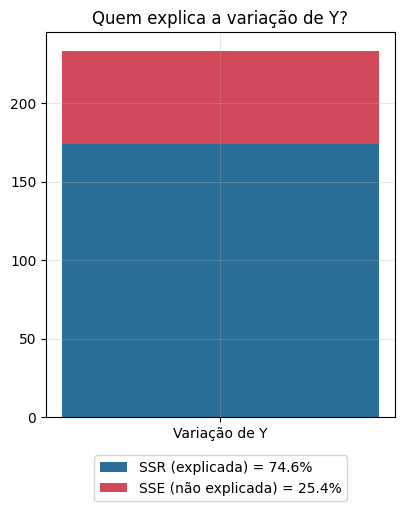

In [8]:
ssto_pv = np.sum((vendas - vendas.mean()) ** 2)
ssr_pv = ssto_pv - sse_pv
r2_pv = ssr_pv / ssto_pv
print(f"SSTO = {ssto_pv:.2f}   SSR = {ssr_pv:.2f}   SSE = {sse_pv:.2f}   (SSR+SSE = {ssr_pv+sse_pv:.2f})")
print(f"r2 = {r2_pv:.4f}  ->  {r2_pv*100:.1f}% das vendas são explicadas pela variação do preço")

fig, ax = plt.subplots(figsize=(4.5, 5))
ax.bar(['Variação de Y'], [ssr_pv], color='#2a6f97', label=f'SSR (explicada) = {r2_pv*100:.1f}%')
ax.bar(['Variação de Y'], [sse_pv], bottom=[ssr_pv], color='#d1495b', label=f'SSE (não explicada) = {(1-r2_pv)*100:.1f}%')
ax.set_title('Quem explica a variação de Y?')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08))
plt.show()

### Usando o Modelo para Previsão, com Erro de Previsão

$$\hat Y = b_0 + bX \qquad s_f = s_\varepsilon\sqrt{1+\frac1n+\frac{(X-\bar X)^2}{\sum(X-\bar X)^2}} \qquad \text{IP:}\;\; \hat Y \pm t\,s_f$$

In [9]:
x0 = 1.63
y0_hat = b0_pv + b_pv * x0
s_f = s_eps_pv * np.sqrt(1 + 1/len(preco) + (x0 - preco.mean())**2 / np.sum((preco - preco.mean())**2))
t95 = st.t.ppf(0.975, gl)
print(f"Previsão para X={x0}: Y_hat = {y0_hat:.3f}")
print(f"s_f = {s_f:.3f}   t(95%, gl={gl}) = {t95:.3f}")
print(f"Intervalo de previsão 95%: [{y0_hat - t95*s_f:.2f} ; {y0_hat + t95*s_f:.2f}]")

Previsão para X=1.63: Y_hat = 8.438
s_f = 2.915   t(95%, gl=8) = 2.306
Intervalo de previsão 95%: [1.72 ; 15.16]


### Análise de Resíduos (ACF)

Um bom modelo deve deixar resíduos sem estrutura (sem autocorrelação). Veremos este ponto com muito mais profundidade no notebook `03_Regressao_Series_Temporais_Durbin_Watson.ipynb` (que trata exatamente do caso em que os resíduos SÃO correlacionados ao longo do tempo).

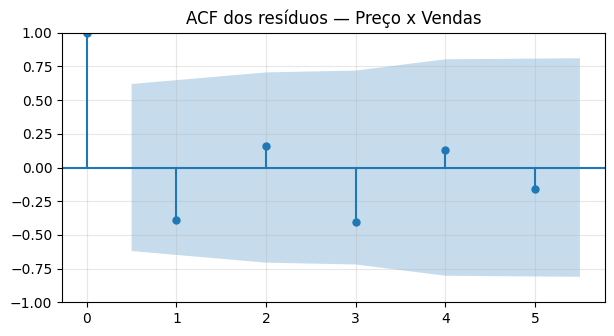

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
plot_acf(residuos_pv, lags=5, alpha=0.05, ax=ax)
ax.set_title('ACF dos resíduos — Preço x Vendas')
plt.show()

## 3. Regressão Linear Multivariada

Acrescentamos uma segunda variável independente: a **verba gasta em publicidade** (milhares de reais).

$$\hat Y = b_0 + b_2 X_2 + b_3 X_3$$

Os coeficientes resolvem o sistema normal (mínimos quadrados multivariados):

$$\sum Y_i = nb_0 + b_2\sum X_{2i} + b_3\sum X_{3i}$$
$$\sum X_{2i}Y_i = b_0\sum X_{2i} + b_2\sum X_{2i}^2 + b_3\sum X_{2i}X_{3i}$$
$$\sum X_{3i}Y_i = b_0\sum X_{3i} + b_2\sum X_{2i}X_{3i} + b_3\sum X_{3i}^2$$

In [11]:
publicidade = np.array([9.0, 7.0, 5.0, 14.0, 15.0, 12.0, 6.0, 10.0, 15.0, 21.0])
df_mv = pd.DataFrame({'Preco': preco, 'Publicidade': publicidade, 'Vendas': vendas})

print("Correlação com Vendas:")
print(df_mv.corr()['Vendas'])

model_mv = ols('Vendas ~ Preco + Publicidade', df_mv).fit()
print("\n", model_mv.params)
print(f"\nR^2 = {model_mv.rsquared:.3f}")
print(model_mv.summary())

Correlação com Vendas:
Preco         -0.863489
Publicidade    0.891497
Vendas         1.000000
Name: Vendas, dtype: float64



 Intercept      16.406365
Preco          -8.247580
Publicidade     0.585101
dtype: float64

R^2 = 0.932
                            OLS Regression Results                            
Dep. Variable:                 Vendas   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     47.92
Date:                Mon, 26 Oct 2026   Prob (F-statistic):           8.23e-05
Time:                        20:19:28   Log-Likelihood:                -16.509
No. Observations:                  10   AIC:                             39.02
Df Residuals:                       7   BIC:                             39.92
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------

C:\Users\PedroOliveira\AppData\Roaming\Python\Python310\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=10 observations were given.
  return hypotest_fun_in(*args, **kwds)


In [12]:
sse_mv = np.sum(model_mv.resid ** 2)
ssto_mv = np.sum((vendas - vendas.mean()) ** 2)
ssr_mv = ssto_mv - sse_mv
print(f"SSE = {sse_mv:.2f}   SSR = {ssr_mv:.2f}   SSTO = {ssto_mv:.2f}")
print(f"r2 = {ssr_mv/ssto_mv:.4f}  (sobe de {r2_pv:.3f} com 1 variável para {ssr_mv/ssto_mv:.3f} com 2)")

SSE = 15.90   SSR = 217.70   SSTO = 233.60
r2 = 0.9319  (sobe de 0.746 com 1 variável para 0.932 com 2)


**Leitura:** ao incluir a publicidade, o $r^2$ sobe de ~0,75 para ~0,93 — ou seja, boa parte dos 25% de variação "não explicada" pelo modelo simples era, na verdade, efeito da publicidade.

## 4. Colinearidade

A colinearidade ocorre quando **variáveis independentes são, elas mesmas, correlacionadas entre si**. Problemas: (1) o sinal de um coeficiente pode se inverter ao incluir outra variável; (2) os coeficientes variam muito de amostra para amostra; (3) fica difícil interpretar a contribuição individual de cada variável.

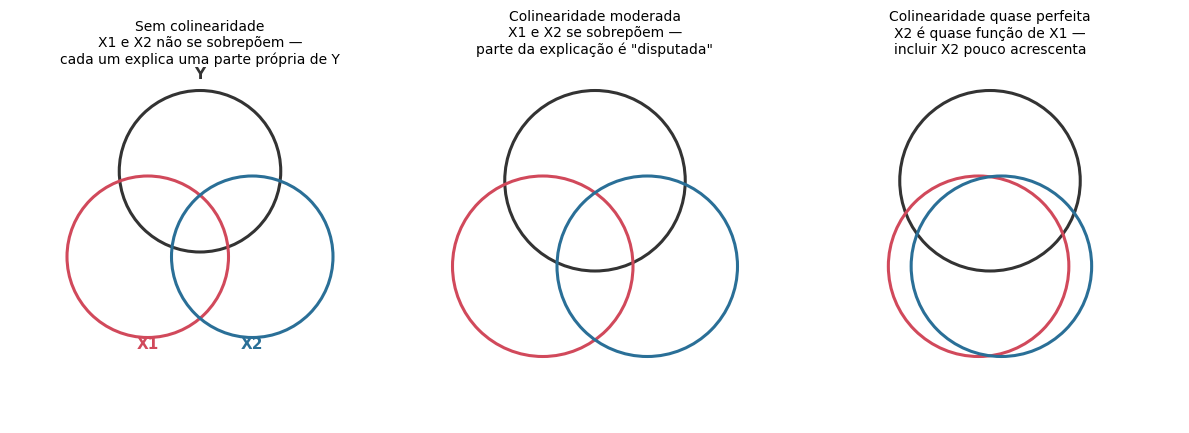

In [13]:
def diagrama_venn_3(ax, offset_xy, titulo, raio=1.0):
    (cx, cy) = offset_xy
    cores = ['#333333', '#d1495b', '#2a6f97']
    centros = [(cx, cy + 0.55), (cx - 0.55, cy - 0.35), (cx + 0.55, cy - 0.35)]
    labels = ['Y', 'X1', 'X2']
    for (x, y), cor, lab in zip(centros, cores, labels):
        ax.add_patch(plt.Circle((x, y), raio, fill=False, lw=2.2, edgecolor=cor))
        ax.annotate(lab, (x, y + (raio + 0.12 if lab == 'Y' else -raio - 0.12)), ha='center',
                    color=cor, fontsize=11, fontweight='bold')
    ax.set_title(titulo, fontsize=10)
    ax.set_xlim(cx - 2, cx + 2); ax.set_ylim(cy - 2, cy + 1.6)
    ax.set_aspect('equal'); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
diagrama_venn_3(axes[0], (0, 0), 'Sem colinearidade\nX1 e X2 não se sobrepõem —\ncada um explica uma parte própria de Y', raio=0.85)

def diagrama_sobreposto(ax, titulo, dist, raio=1.0):
    cores = ['#333333', '#d1495b', '#2a6f97']
    centros = [(0, 0.55), (-dist, -0.35), (dist, -0.35)]
    labels = ['Y', 'X1', 'X2']
    for (x, y), cor, lab in zip(centros, cores, labels):
        ax.add_patch(plt.Circle((x, y), raio, fill=False, lw=2.2, edgecolor=cor))
    ax.set_title(titulo, fontsize=10)
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 1.8)
    ax.set_aspect('equal'); ax.axis('off')

diagrama_sobreposto(axes[1], 'Colinearidade moderada\nX1 e X2 se sobrepõem —\nparte da explicação é "disputada"', dist=0.55, raio=0.95)
diagrama_sobreposto(axes[2], 'Colinearidade quase perfeita\nX2 é quase função de X1 —\nincluir X2 pouco acrescenta', dist=0.12, raio=0.95)
fig.tight_layout()
plt.show()

### Exemplo de colinearidade: gasto com alimentação, renda e tamanho da família

Ambas variáveis (renda, tamanho da família) têm correlação **positiva** com o gasto — mas, se forem muito correlacionadas *entre si*, o modelo multivariado pode atribuir um sinal **errado** a uma delas.

In [14]:
renda = np.array([11, 3, 4, 7, 9, 8, 5, 7, 8, 7])
tamanho = np.array([6, 2, 1, 3, 5, 4, 2, 2, 3, 2])
gasto = np.array([24, 8, 16, 18, 24, 23, 11, 15, 21, 20])
df_col = pd.DataFrame({'Renda': renda, 'Tamanho': tamanho, 'Gasto': gasto})

print("Matriz de correlação:")
print(df_col.corr())

model_col = ols('Gasto ~ Renda + Tamanho', df_col).fit()
print("\nCoeficientes do modelo multivariado:")
print(model_col.params)
print("\n-> Note que 'Tamanho' tem correlação POSITIVA com Gasto, mas seu coeficiente na regressão")
print("   multivariada pode sair NEGATIVO: sintoma clássico de colinearidade (Renda e Tamanho são")
print("   fortemente correlacionadas entre si, 'competindo' pela mesma variação de Y).")

Matriz de correlação:
            Renda   Tamanho     Gasto
Renda    1.000000  0.866618  0.883873
Tamanho  0.866618  1.000000  0.736850
Gasto    0.883873  0.736850  1.000000

Coeficientes do modelo multivariado:
Intercept    3.518651
Renda        2.277618
Tamanho     -0.411406
dtype: float64

-> Note que 'Tamanho' tem correlação POSITIVA com Gasto, mas seu coeficiente na regressão
   multivariada pode sair NEGATIVO: sintoma clássico de colinearidade (Renda e Tamanho são
   fortemente correlacionadas entre si, 'competindo' pela mesma variação de Y).


## 5. Seleção de Variáveis Independentes

**Exemplo:** prever o desempenho de um vendedor no 1º mês (Y) a partir de: nota de aptidão para vendas ($X_2$), idade ($X_3$), nota de ansiedade ($X_4$), anos de experiência anterior ($X_5$) e média do ensino médio ($X_6$). Dataset com 30 observações (slides, Aula 07).

In [15]:
vendedores = pd.DataFrame({
    'Vendas':   [44,47,60,71,61,60,58,56,66,61,51,47,53,74,65, 33,54,39,52,30,58,59,52,56,49,63,61,39,62,78],
    'Teste':    [10,19,27,31,64,81,42,67,48,64,57,10,48,96,75, 12,47,20,73,4,9,98,27,59,23,90,34,16,32,94],
    'Idade':    [21.1,22.5,23.1,24.0,22.6,21.7,23.8,22.0,22.4,22.6,21.1,22.5,22.2,24.8,22.6,
                 20.5,21.9,20.5,20.8,20.0,23.3,21.3,22.9,22.3,22.6,22.4,23.8,20.6,24.4,25.0],
    'Ansiedade':[4.9,3.0,1.5,0.6,1.8,3.3,3.2,2.1,6.0,1.8,3.8,4.5,4.5,0.1,0.9,
                 4.8,2.3,3.0,0.3,2.7,4.4,3.9,1.4,2.7,2.7,2.2,0.7,3.1,0.6,4.6],
    'Experiencia':[0,1,0,3,2,1,0,0,1,1,0,1,0,3,0, 0,1,2,2,0,1,1,2,1,1,2,1,1,3,5],
    'Media':    [2.4,2.6,2.8,2.7,2.0,2.5,2.5,2.3,2.8,3.4,3.0,2.7,2.8,3.8,3.7,
                 2.1,1.8,1.5,1.9,2.2,2.8,2.9,3.2,2.7,2.4,2.6,3.4,2.3,4.0,3.6],
})
print(vendedores.corr()['Vendas'])

Vendas         1.000000
Teste          0.676120
Idade          0.811956
Ansiedade     -0.295860
Experiencia    0.549834
Media          0.621784
Name: Vendas, dtype: float64


### Método Exaustivo

Testa **todas** as $2^n$ combinações possíveis de variáveis independentes e escolhe, para cada tamanho de subconjunto, a de maior $r^2$ — favorecendo, entre empates/proximidades, o modelo mais parcimonioso (menos variáveis).

In [16]:
variaveis = ['Teste', 'Idade', 'Ansiedade', 'Experiencia', 'Media']
melhores_por_tamanho = {}
for k in range(1, len(variaveis) + 1):
    melhor_r2, melhor_combo = -1, None
    for combo in itertools.combinations(variaveis, k):
        formula = 'Vendas ~ ' + ' + '.join(combo)
        r2 = ols(formula, vendedores).fit().rsquared
        if r2 > melhor_r2:
            melhor_r2, melhor_combo = r2, combo
    melhores_por_tamanho[k] = (melhor_combo, melhor_r2)
    print(f"k={k}: melhor combinação = {melhor_combo}  ->  r2 = {melhor_r2:.4f}")

k=1: melhor combinação = ('Idade',)  ->  r2 = 0.6593
k=2: melhor combinação = ('Teste', 'Idade')  ->  r2 = 0.8935
k=3: melhor combinação = ('Teste', 'Idade', 'Ansiedade')  ->  r2 = 0.8947
k=4: melhor combinação = ('Teste', 'Idade', 'Ansiedade', 'Media')  ->  r2 = 0.8951
k=5: melhor combinação = ('Teste', 'Idade', 'Ansiedade', 'Experiencia', 'Media')  ->  r2 = 0.8952


**Leitura:** o ganho de $r^2$ ao passar de 1 para 2 variáveis (Idade + Teste) é grande; daí em diante, cada nova variável acrescenta muito pouco — um sinal claro de que **2 variáveis já bastam** (princípio da parcimônia).

> **Nota sobre os números do slide original:** a tabela de seleção exaustiva do slide da Aula 07 mostra $r^2=0{,}637$ para o modelo só com `Idade`, mas o próprio slide também informa $\text{corr}(\text{Idade}, \text{Vendas}) = 0{,}811956$ — e $0{,}811956^2 = 0{,}6593$, batendo com o valor recalculado aqui (0,6593), não com 0,637. É um pequeno erro de transcrição do slide original (o mesmo tipo de inconsistência que o notebook de referência de ARIMA já apontava em outros pontos do material do curso) — os valores calculados neste notebook, diretamente dos dados, são os corretos.

### Método Aditivo (*stepwise* / *forward selection*)

Em cada iteração, entra a variável que resulta na maior estatística $t$ (em módulo) para o novo coeficiente; o processo para quando nenhuma variável candidata é significativa.

In [17]:
def selecao_aditiva(y_col, candidatas, dados, alpha=0.05, verbose=True):
    selecionadas = []
    restantes = list(candidatas)
    historico = []
    while restantes:
        melhor_t, melhor_var, melhor_fit = 0, None, None
        for var in restantes:
            formula = f'{y_col} ~ ' + ' + '.join(selecionadas + [var])
            fit = ols(formula, dados).fit()
            t_val = abs(fit.tvalues[var])
            if t_val > melhor_t:
                melhor_t, melhor_var, melhor_fit = t_val, var, fit
        p_val = melhor_fit.pvalues[melhor_var]
        if p_val < alpha:
            selecionadas.append(melhor_var)
            restantes.remove(melhor_var)
            historico.append((melhor_var, melhor_t, p_val, melhor_fit.rsquared))
            if verbose:
                print(f"+ entra '{melhor_var}'  (t={melhor_t:.2f}, p={p_val:.4f})  -> r2 = {melhor_fit.rsquared:.4f}")
        else:
            if verbose:
                print(f"Nenhuma variável restante é significativa (melhor seria '{melhor_var}', p={p_val:.4f}) -> processo encerrado")
            break
    return selecionadas, historico

sel, hist = selecao_aditiva('Vendas', variaveis, vendedores)
print("\nModelo final (método aditivo):", 'Vendas ~ ' + ' + '.join(sel))
print(ols('Vendas ~ ' + ' + '.join(sel), vendedores).fit().summary().tables[1])

+ entra 'Idade'  (t=7.36, p=0.0000)  -> r2 = 0.6593
+ entra 'Teste'  (t=7.70, p=0.0000)  -> r2 = 0.8935
Nenhuma variável restante é significativa (melhor seria 'Ansiedade', p=0.5792) -> processo encerrado

Modelo final (método aditivo): Vendas ~ Idade + Teste


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -84.8405     12.265     -6.917      0.000    -110.006     -59.675
Idade          5.8694      0.558     10.516      0.000       4.724       7.015
Teste          0.1918      0.025      7.704      0.000       0.141       0.243


## 6. Variáveis "Dummy" para Categorias

Quando um dado é categórico (ex.: trimestre do ano, terminal A ou B) em vez de numérico, criamos variáveis indicadoras 0/1. Veremos isso na prática no **Exercício 3** abaixo.

---
## Exercícios

### Exercício 1 — Vendas de e-commerce x aparições em comerciais

Nível de vendas (milhares) em função do número de aparições em comerciais de TV, em 12 cidades.

a) r = 0.6913  -> correlação linear positiva moderada
b) Vendas_hat = 16.084 + 1.103 x Aparicoes   (r2=0.478)
c) s_eps = 5.839
d) r2 = 0.478  ->  47.8% das vendas explicadas pelas aparições em TV
e) t = 3.025   t_critico(1%, gl=10) = 3.169  -> não rejeita H0
f) previsão para 10 aparições: 27.12 mil unidades


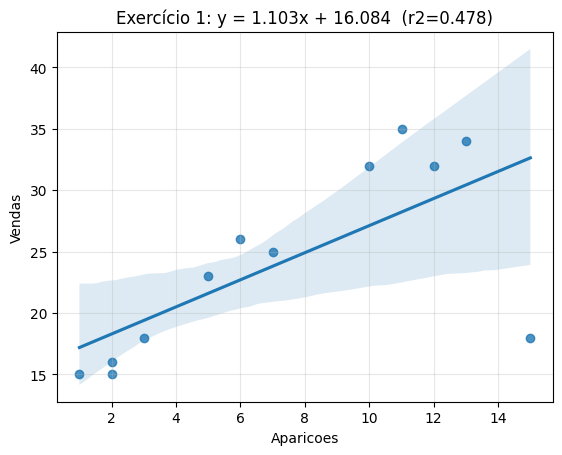

In [18]:
vendas_ex1 = np.array([26,16,23,15,32,25,18,18,35,34,15,32])
aparicoes_ex1 = np.array([6,2,5,1,10,7,15,3,11,13,2,12])
df_ex1 = pd.DataFrame({'Vendas': vendas_ex1, 'Aparicoes': aparicoes_ex1})

# a) correlação
r_ex1 = np.corrcoef(aparicoes_ex1, vendas_ex1)[0, 1]
print(f"a) r = {r_ex1:.4f}  -> correlação linear positiva {'forte' if r_ex1>0.7 else 'moderada'}")

# b) curva de regressão
m1 = ols('Vendas ~ Aparicoes', df_ex1).fit()
b0_1, b_1 = m1.params['Intercept'], m1.params['Aparicoes']
print(f"b) Vendas_hat = {b0_1:.3f} + {b_1:.3f} x Aparicoes   (r2={m1.rsquared:.3f})")

# c) erro padrão da estimativa
sse1 = np.sum(m1.resid**2); gl1 = len(vendas_ex1) - 2
s_eps1 = np.sqrt(sse1/gl1)
print(f"c) s_eps = {s_eps1:.3f}")

# d) percentual explicado
print(f"d) r2 = {m1.rsquared:.3f}  ->  {m1.rsquared*100:.1f}% das vendas explicadas pelas aparições em TV")

# e) teste de hipótese do coeficiente angular, alpha=1%
s_b1 = s_eps1 / np.sqrt(np.sum((aparicoes_ex1 - aparicoes_ex1.mean())**2))
t1 = b_1 / s_b1
t_crit1 = st.t.ppf(0.995, gl1)
print(f"e) t = {t1:.3f}   t_critico(1%, gl={gl1}) = {t_crit1:.3f}  ->",
      "rejeita H0, coeficiente significativo" if abs(t1) > t_crit1 else "não rejeita H0")

# f) previsão para 10 aparições
pred10 = b0_1 + b_1 * 10
print(f"f) previsão para 10 aparições: {pred10:.2f} mil unidades")

sns.regplot(x='Aparicoes', y='Vendas', data=df_ex1, ci=95)
plt.title(f"Exercício 1: y = {b_1:.3f}x + {b0_1:.3f}  (r2={m1.rsquared:.3f})")
plt.show()

### Exercício 2 — Efeito do tamanho da amostra no intervalo de previsão

Usando os dados reais de `2.5/07 - Dados Ex 02.txt`, vamos gerar **2 amostras diferentes** para cada tamanho $n \in \{20, 40, 60, 80, 100\}$ e comparar o intervalo de previsão (IP 95%) para $X=305$. Esperado: quanto maior $n$, mais estreito (mais confiável) o IP.

In [19]:
dados_ex2 = pd.read_csv('2.5/07 - Dados Ex 02.txt', sep='\t')
print(dados_ex2.shape, dados_ex2.columns.tolist())
dados_ex2.head()

(140, 2) ['X', 'Y']


,X,Y
0,10,1.0
1,10,0.9
2,10,0.8
3,20,1.3
4,20,0.9


     n  amostra  Y_hat  IP_inf  IP_sup  largura
0   20        1   2.51    1.64    3.39     1.75
1   20        2   2.34    1.39    3.28     1.89
2   40        1   2.40    1.63    3.18     1.56
3   40        2   2.32    1.52    3.11     1.60
4   60        1   2.38    1.66    3.10     1.45
5   60        2   2.33    1.56    3.09     1.52
6   80        1   2.42    1.55    3.29     1.74
7   80        2   2.32    1.57    3.07     1.51
8  100        1   2.42    1.56    3.28     1.73
9  100        2   2.34    1.59    3.09     1.50


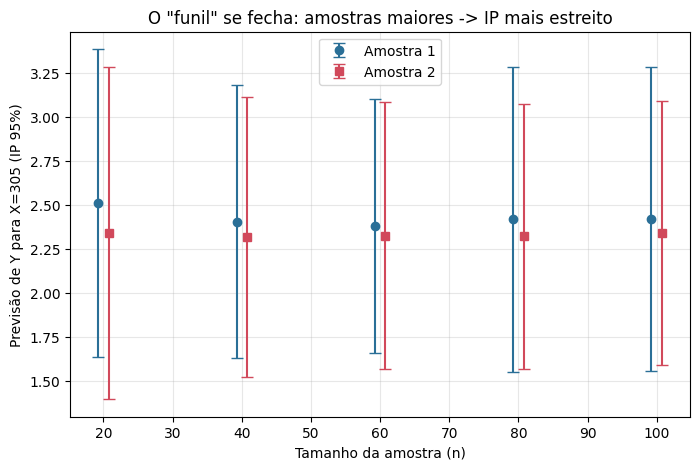

In [20]:
def ip_para_x0(dados, x0, seed):
    g = np.random.default_rng(seed)
    idx = g.choice(dados.index, size=len(dados), replace=False)
    amostra = dados.loc[idx]
    m = ols('Y ~ X', amostra).fit()
    b0, b = m.params['Intercept'], m.params['X']
    sse = np.sum(m.resid**2); gl = len(amostra) - 2
    s_eps = np.sqrt(sse/gl)
    s_f = s_eps * np.sqrt(1 + 1/len(amostra) + (x0 - amostra['X'].mean())**2 / np.sum((amostra['X']-amostra['X'].mean())**2))
    y0 = b0 + b*x0
    t95 = st.t.ppf(0.975, gl)
    return y0, y0 - t95*s_f, y0 + t95*s_f

x0 = 305
tamanhos = [20, 40, 60, 80, 100]
resultados = []
for n in tamanhos:
    for amostra_id, seed in enumerate([1, 2]):
        base = dados_ex2.sample(n=min(n, len(dados_ex2)), random_state=seed, replace=(n > len(dados_ex2)))
        y0, inf, sup = ip_para_x0(base, x0, seed)
        resultados.append({'n': n, 'amostra': amostra_id+1, 'Y_hat': y0, 'IP_inf': inf, 'IP_sup': sup, 'largura': sup-inf})
res_df = pd.DataFrame(resultados)
print(res_df.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for amostra_id, cor, marcador in [(1, '#2a6f97', 'o'), (2, '#d1495b', 's')]:
    sub = res_df[res_df.amostra == amostra_id]
    ax.errorbar(sub['n'] + (amostra_id-1.5)*1.5, sub['Y_hat'],
                yerr=[sub['Y_hat']-sub['IP_inf'], sub['IP_sup']-sub['Y_hat']],
                fmt=marcador, color=cor, capsize=4, label=f'Amostra {amostra_id}')
ax.set_xlabel('Tamanho da amostra (n)'); ax.set_ylabel(f'Previsão de Y para X={x0} (IP 95%)')
ax.set_title('O "funil" se fecha: amostras maiores -> IP mais estreito')
ax.legend()
plt.show()

**Conclusão:** como esperado, a largura do intervalo de previsão **diminui** conforme $n$ cresce — mais dados reduzem a incerteza tanto do erro padrão da estimativa quanto da estimativa da média de $X$.

### Exercício 3 — Regressão com variáveis Dummy sazonais

Consumo trimestral de energia (kWh) de uma empresa ao longo de 16+ anos. Queremos prever o consumo usando variáveis indicadoras de trimestre: $S_2, S_3, S_4$ valem 1 se o trimestre for o 1º, 2º ou 3º do ano, respectivamente (e 0 caso contrário) — o 4º trimestre fica implícito no intercepto (categoria de referência).

$$\hat Y = b_0 + b_2 S_2 + b_3 S_3 + b_4 S_4$$

Intercept    770.062500
S2           229.290441
S3          -111.709559
S4          -242.312500
dtype: float64

R^2 = 0.914


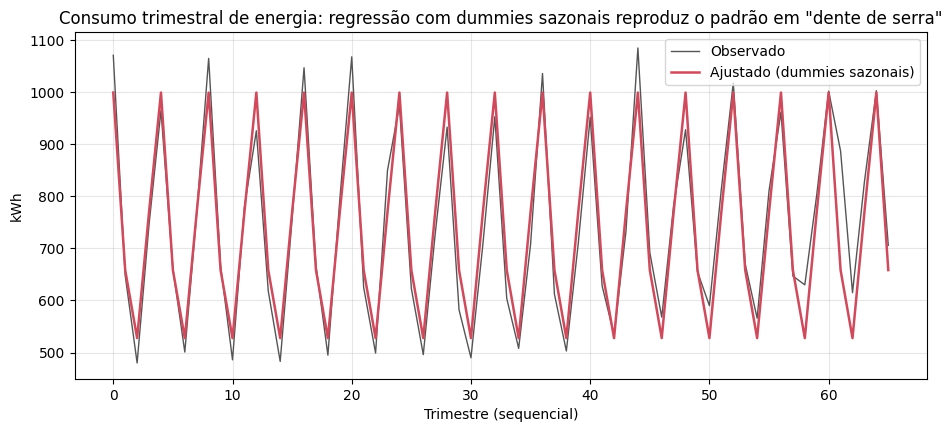

In [21]:
kwh = [1071,648,480,746, 965,661,501,768, 1065,667,486,780, 926,618,483,757,
       1047,667,495,794, 1068,625,499,850, 975,623,496,728, 933,582,490,708,
       953,604,508,708, 1036,612,503,710, 952,628,534,733, 1085,692,568,783,
       928,655,590,814, 1018,670,566,811, 962,647,630,803, 1002,887,615,828,
       1003,706]
trimestres = [(t % 4) + 1 for t in range(len(kwh))]  # 1,2,3,4,1,2,3,4,...

df_kwh = pd.DataFrame({'kWh': kwh, 'Trimestre': trimestres})
df_kwh['S2'] = (df_kwh['Trimestre'] == 1).astype(int)
df_kwh['S3'] = (df_kwh['Trimestre'] == 2).astype(int)
df_kwh['S4'] = (df_kwh['Trimestre'] == 3).astype(int)
# (convenção do slide: S2 marca o 1o tri, S3 o 2o, S4 o 3o; o 4o trimestre é a categoria-base)

model_kwh = ols('kWh ~ S2 + S3 + S4', df_kwh).fit()
print(model_kwh.params)
print(f"\nR^2 = {model_kwh.rsquared:.3f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(range(len(kwh)), kwh, color='#555', lw=1, label='Observado')
ax.plot(range(len(kwh)), model_kwh.fittedvalues, color='#d1495b', lw=1.8, label='Ajustado (dummies sazonais)')
ax.set_title('Consumo trimestral de energia: regressão com dummies sazonais reproduz o padrão em "dente de serra"')
ax.set_xlabel('Trimestre (sequencial)'); ax.set_ylabel('kWh')
ax.legend()
plt.show()

**Leitura:** mesmo sem nenhuma variável de tendência explícita, as 3 dummies conseguem capturar o padrão sazonal repetitivo (pico no 1º trimestre, vale no 3º). Esse é o uso mais simples de variáveis dummy para sazonalidade — uma alternativa ao Holt-Winters do notebook `01`, mais rígida (sazonalidade fixa, sem variar com o tempo) mas fácil de interpretar via regressão.

### Exercício 4 — Seleção aditiva de variáveis: preço de imóveis

Dataset real (`2.5/07 - Dados Ex 04.xlsx`, 1000 imóveis, 12 variáveis candidatas). Vamos aplicar o **método aditivo** (mesma função `selecao_aditiva` definida na Seção 5) para encontrar o melhor subconjunto de variáveis que explica o preço.

In [22]:
imoveis = pd.read_excel('2.5/07 - Dados Ex 04.xlsx', sheet_name='ex')
imoveis = imoveis.rename(columns={
    'Área (m2)': 'Area', '# Quartos': 'Quartos', '# Banheiros': 'Banheiros',
    'Idade (anos)': 'Idade', 'Distância_centro (km)': 'Distancia',
    'Índice_Escolas': 'IndiceEscolas', 'Índice_Criminalidade': 'IndiceCriminalidade',
    'Preço (R$)': 'Preco',
})
candidatas_imoveis = ['Area', 'Quartos', 'Banheiros', 'Idade', 'Distancia', 'Garagem',
                       'IndiceEscolas', 'IndiceCriminalidade', 'Zona_Norte', 'Zona_Sul', 'Zona_Leste']
print(imoveis[candidatas_imoveis + ['Preco']].corr()['Preco'].sort_values(ascending=False))

Preco                  1.000000
Quartos                0.668389
Banheiros              0.660537
Area                   0.625096
IndiceEscolas          0.053365
Zona_Norte             0.035095
Zona_Leste             0.025608
Garagem               -0.027022
IndiceCriminalidade   -0.050029
Idade                 -0.058508
Zona_Sul              -0.088418
Distancia             -0.146051
Name: Preco, dtype: float64


+ entra 'Quartos'  (t=28.39, p=0.0000)  -> r2 = 0.4467
+ entra 'Area'  (t=50.46, p=0.0000)  -> r2 = 0.8443
+ entra 'Distancia'  (t=12.29, p=0.0000)  -> r2 = 0.8648
+ entra 'Banheiros'  (t=12.27, p=0.0000)  -> r2 = 0.8826
+ entra 'Idade'  (t=11.46, p=0.0000)  -> r2 = 0.8963


+ entra 'IndiceEscolas'  (t=9.56, p=0.0000)  -> r2 = 0.9050


+ entra 'Zona_Sul'  (t=6.94, p=0.0000)  -> r2 = 0.9094
+ entra 'IndiceCriminalidade'  (t=5.78, p=0.0000)  -> r2 = 0.9124
+ entra 'Zona_Leste'  (t=5.39, p=0.0000)  -> r2 = 0.9149
+ entra 'Garagem'  (t=3.20, p=0.0014)  -> r2 = 0.9157
+ entra 'Zona_Norte'  (t=2.60, p=0.0096)  -> r2 = 0.9163

Modelo final (seleção aditiva): Preco ~ Quartos + Area + Distancia + Banheiros + Idade + IndiceEscolas + Zona_Sul + IndiceCriminalidade + Zona_Leste + Garagem + Zona_Norte
R^2 final = 0.9163


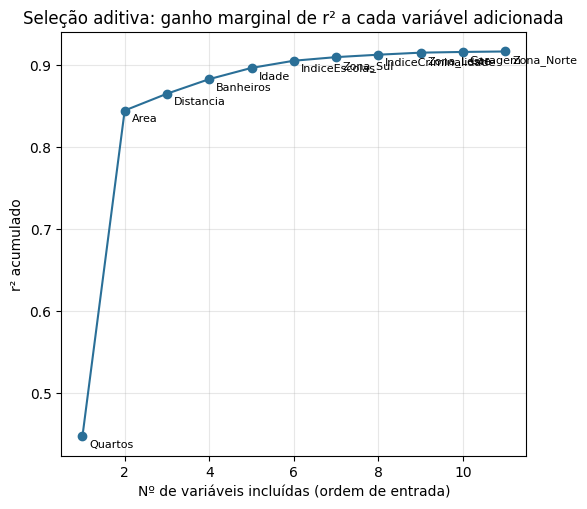

In [23]:
sel_imoveis, hist_imoveis = selecao_aditiva('Preco', candidatas_imoveis, imoveis, alpha=0.05)
print("\nModelo final (seleção aditiva):", 'Preco ~ ' + ' + '.join(sel_imoveis))

modelo_final_imoveis = ols('Preco ~ ' + ' + '.join(sel_imoveis), imoveis).fit()
print(f"R^2 final = {modelo_final_imoveis.rsquared:.4f}")

fig, ax = plt.subplots(figsize=(6, 5.5))
r2_evolucao = [h[3] for h in hist_imoveis]
ax.plot(range(1, len(r2_evolucao)+1), r2_evolucao, 'o-', color='#2a6f97')
for i, (var, t, p, r2) in enumerate(hist_imoveis, start=1):
    ax.annotate(var, (i, r2), textcoords='offset points', xytext=(5, -8), fontsize=8)
ax.set_xlabel('Nº de variáveis incluídas (ordem de entrada)'); ax.set_ylabel('r² acumulado')
ax.set_title('Seleção aditiva: ganho marginal de r² a cada variável adicionada')
plt.show()

**Leitura:** como em qualquer seleção aditiva, as primeiras variáveis (tipicamente `Area` e localização) respondem pela maior fatia do $r^2$; as últimas entram porque ainda são estatisticamente significativas, mas contribuem pouco — de novo, o princípio da parcimônia: um modelo com menos variáveis, quase tão bom quanto o completo, costuma generalizar melhor para dados novos.

---
*Próximo notebook da sequência: [`03_Regressao_Series_Temporais_Durbin_Watson.ipynb`](03_Regressao_Series_Temporais_Durbin_Watson.ipynb) — o que fazer quando os resíduos da regressão são correlacionados ao longo do tempo.*